# Pharmacogene variation across ancestries

A walkthrough of the analysis. Each section states a question, shows the figure that answers it,
and gives the numbers behind the figure.

**What this asks.** Genes that decide how a person metabolises a drug differ in frequency between
ancestry groups. We measure how much, for 107 genes with a CPIC guideline, and ask whether those
genes stand out from ordinary genes.

**Data.** gnomAD v4 allele frequencies, CPIC gene-drug pairs, HGNC gene names. All open, all
scripted in `scripts/`.

**Runtime.** Under a minute. The notebook reads results from `data/processed/` and figures from
`figures/`. It does not re-run the data pulls, which take about an hour.

**Requirements.** pandas, numpy, matplotlib. To regenerate the inputs, see the last section.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
ROOT = ROOT if (ROOT / "figures").exists() else ROOT.parent
PROC, RAW, FIG = ROOT / "data/processed", ROOT / "data/raw", ROOT / "figures"

pd.set_option("display.precision", 3)

def figure(name, width=950):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

genes = pd.read_csv(PROC / "gene_divergence.csv")
variants = pd.read_csv(PROC / "variant_tests.csv")
background = pd.read_csv(PROC / "background_gene_fst.csv")
levels = pd.read_csv(PROC / "gene_levels.csv")
carriers = pd.read_csv(PROC / "carrier_rates.csv")

## 2. The questions

1. Which pharmacogenes differ most between East Asian and South Asian reference groups?
2. Do genes with an actionable CPIC guideline (level A) diverge more than other pharmacogenes?
3. For the variants that already carry a dosing guideline, how many people in each group carry one?
4. Do pharmacogenes as a class diverge more than ordinary genes?

Questions 2 and 4 are framed so that a null result is informative. We expected both to be null.

## 3. The data

One row per variant, per gene, with allele counts for eight gnomAD groups. We keep variants with
at least 1000 alleles observed in both groups and a minor allele frequency of at least 1% in at
least one of them. A gene enters the analysis if it has at least 5 such variants.

In [2]:
pd.DataFrame({
    "set": ["CPIC pharmacogenes", "random genes (baseline)"],
    "genes analysed": [len(genes), len(background)],
    "common variants": [len(variants), background.n_var.sum()],
    "median variants per gene": [genes.n_var.median(), background.n_var.median()],
})

,set,genes analysed,common variants,median variants per gene
0,CPIC pharmacogenes,107,3313,15.0
1,random genes (baseline),81,1310,13.0


## 4. How divergence is measured

Hudson's FST, as recommended by Bhatia et al. (2013), compares allele frequencies in two groups.
For one variant with frequencies $p_1$ and $p_2$ in samples of $n_1$ and $n_2$ alleles:

$$
\mathrm{num} = (p_1 - p_2)^2 - \frac{p_1(1-p_1)}{n_1 - 1} - \frac{p_2(1-p_2)}{n_2 - 1},
\qquad
\mathrm{den} = p_1(1-p_2) + p_2(1-p_1)
$$

The subtracted terms correct for sampling noise, so a variant measured in few people does not look
divergent by accident.

A gene's value pools its variants: numerators summed, denominators summed, then divided. This is a
ratio of averages, not an average of ratios. Taking the median or the mean of per-variant FST gives
a different and less stable number. For VKORC1 the median would be 0.02 and the pooled value is
0.40.

In [3]:
v = variants[variants.gene == "VKORC1"]
num = (v.p_eas - v.p_sas) ** 2 - v.p_eas * (1 - v.p_eas) / (v.an_eas - 1) - v.p_sas * (1 - v.p_sas) / (v.an_sas - 1)
den = v.p_eas * (1 - v.p_sas) + v.p_sas * (1 - v.p_eas)

print(f"VKORC1: {len(v)} common variants")
print(f"pooled FST       {num.sum() / den.sum():.3f}")
print(f"median per-variant FST {np.median(num / den):.3f}")

VKORC1: 7 common variants
pooled FST       0.405
median per-variant FST 0.019


## 5. Which genes differ most

Figure F1 ranks the top 15 of 107 genes. The grey band is where random genes sit, so it says what
an ordinary gene looks like on the same scale.

The hollow marker is the same gene with its single most divergent variant removed. It answers a
question the ranking alone cannot: is this gene broadly divergent, or does one site carry it?

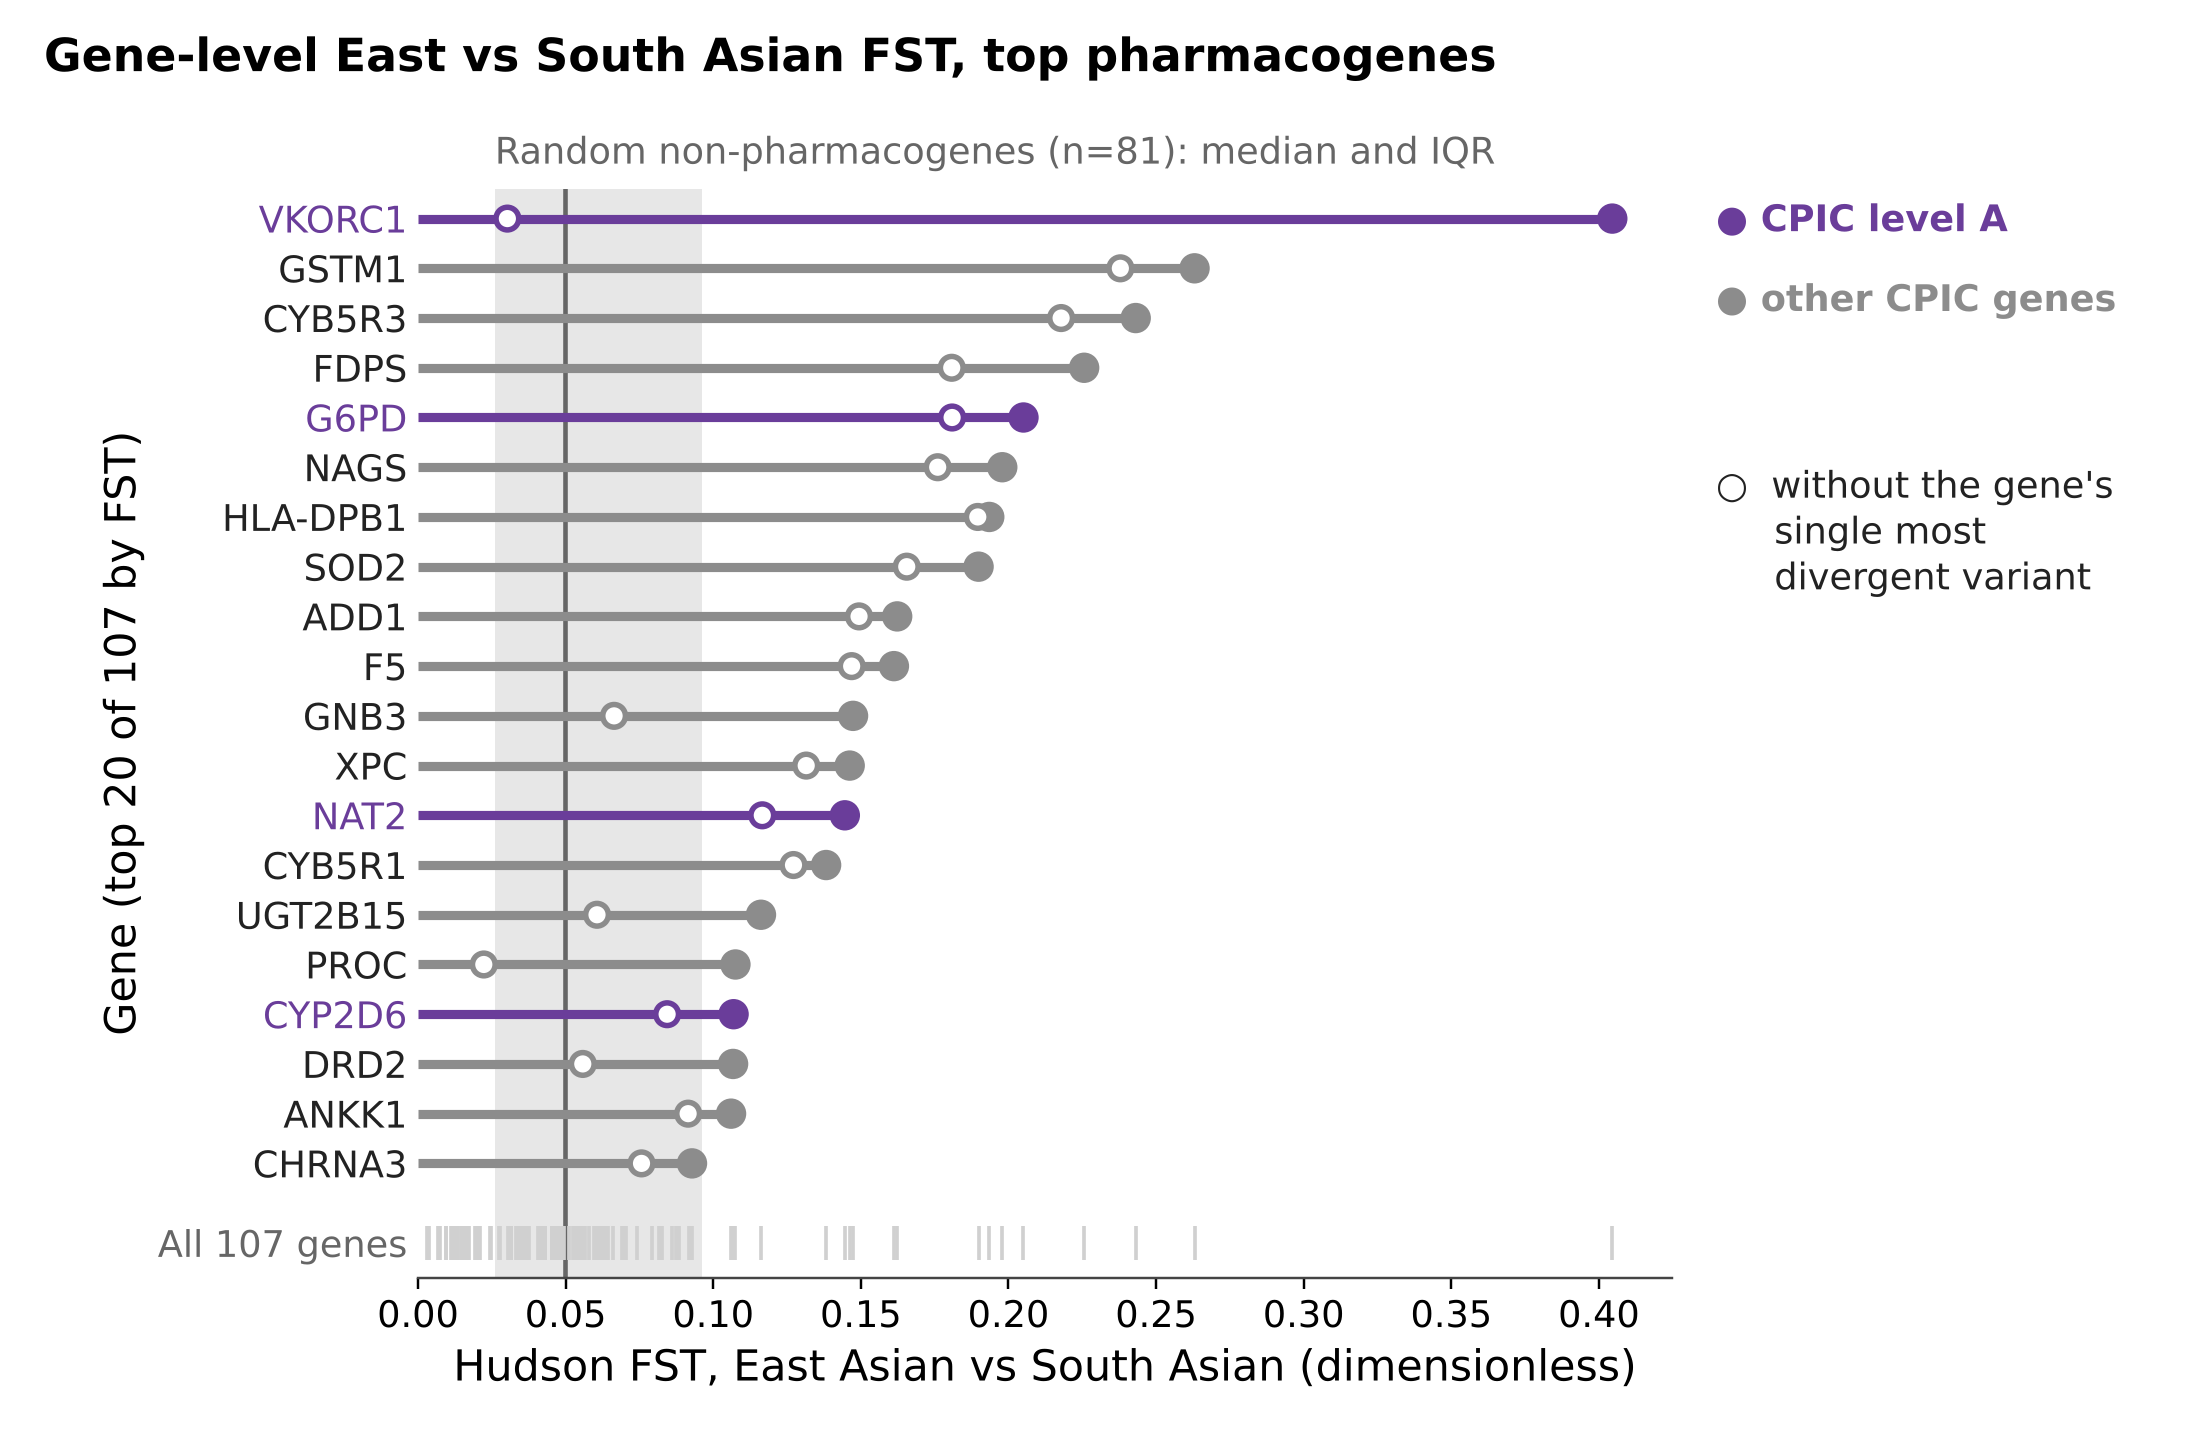

In [4]:
figure("f1_gene_ranking")

In [5]:
top = genes.sort_values("fst", ascending=False).head(8)
top = top[["genesymbol", "fst", "fst_drop1", "n_var", "level_A"]]
top["drop"] = top.fst - top.fst_drop1
top.rename(columns={"genesymbol": "gene", "fst_drop1": "without top variant"}).reset_index(drop=True)

,gene,fst,without top variant,n_var,level_A,drop
0,VKORC1,0.405,0.030,7,True,0.374
1,GSTM1,0.263,0.238,11,False,0.025
2,CYB5R3,0.243,0.218,11,False,0.025
3,FDPS,0.226,0.181,8,False,0.045
4,G6PD,0.205,0.181,7,True,0.024
5,NAGS,0.198,0.176,6,False,0.022
6,HLA-DPB1,0.193,0.190,82,False,0.004
7,SOD2,0.190,0.166,12,False,0.024


**Reading.** VKORC1 is the clear outlier at FST 0.40 against a pharmacogene median of 0.047.
Remove its most divergent variant and it falls to 0.030, which is inside the random-gene band and
below the median of an ordinary gene. No other gene in the list moves appreciably: GSTM1 goes from
0.263 to 0.238.

So VKORC1 the gene is unremarkable. One site in it is not. That site is the promoter variant used
in the CPIC warfarin dosing guideline, which is the point the whole project turns on: what matters
clinically is where a difference lands, not how large the gene-level average is.

## 6. Significance is not effect size

With hundreds of thousands of alleles per group, almost any difference reaches statistical
significance. Figure F7 tests every common variant and corrects for multiple testing with
Benjamini-Hochberg.

The y axis is logarithmic because the adjusted p-values run from 1 down to $10^{-12482}$. Nothing
is clipped. The grey band marks differences we judge too small to act on, which is a judgement, not
a result.

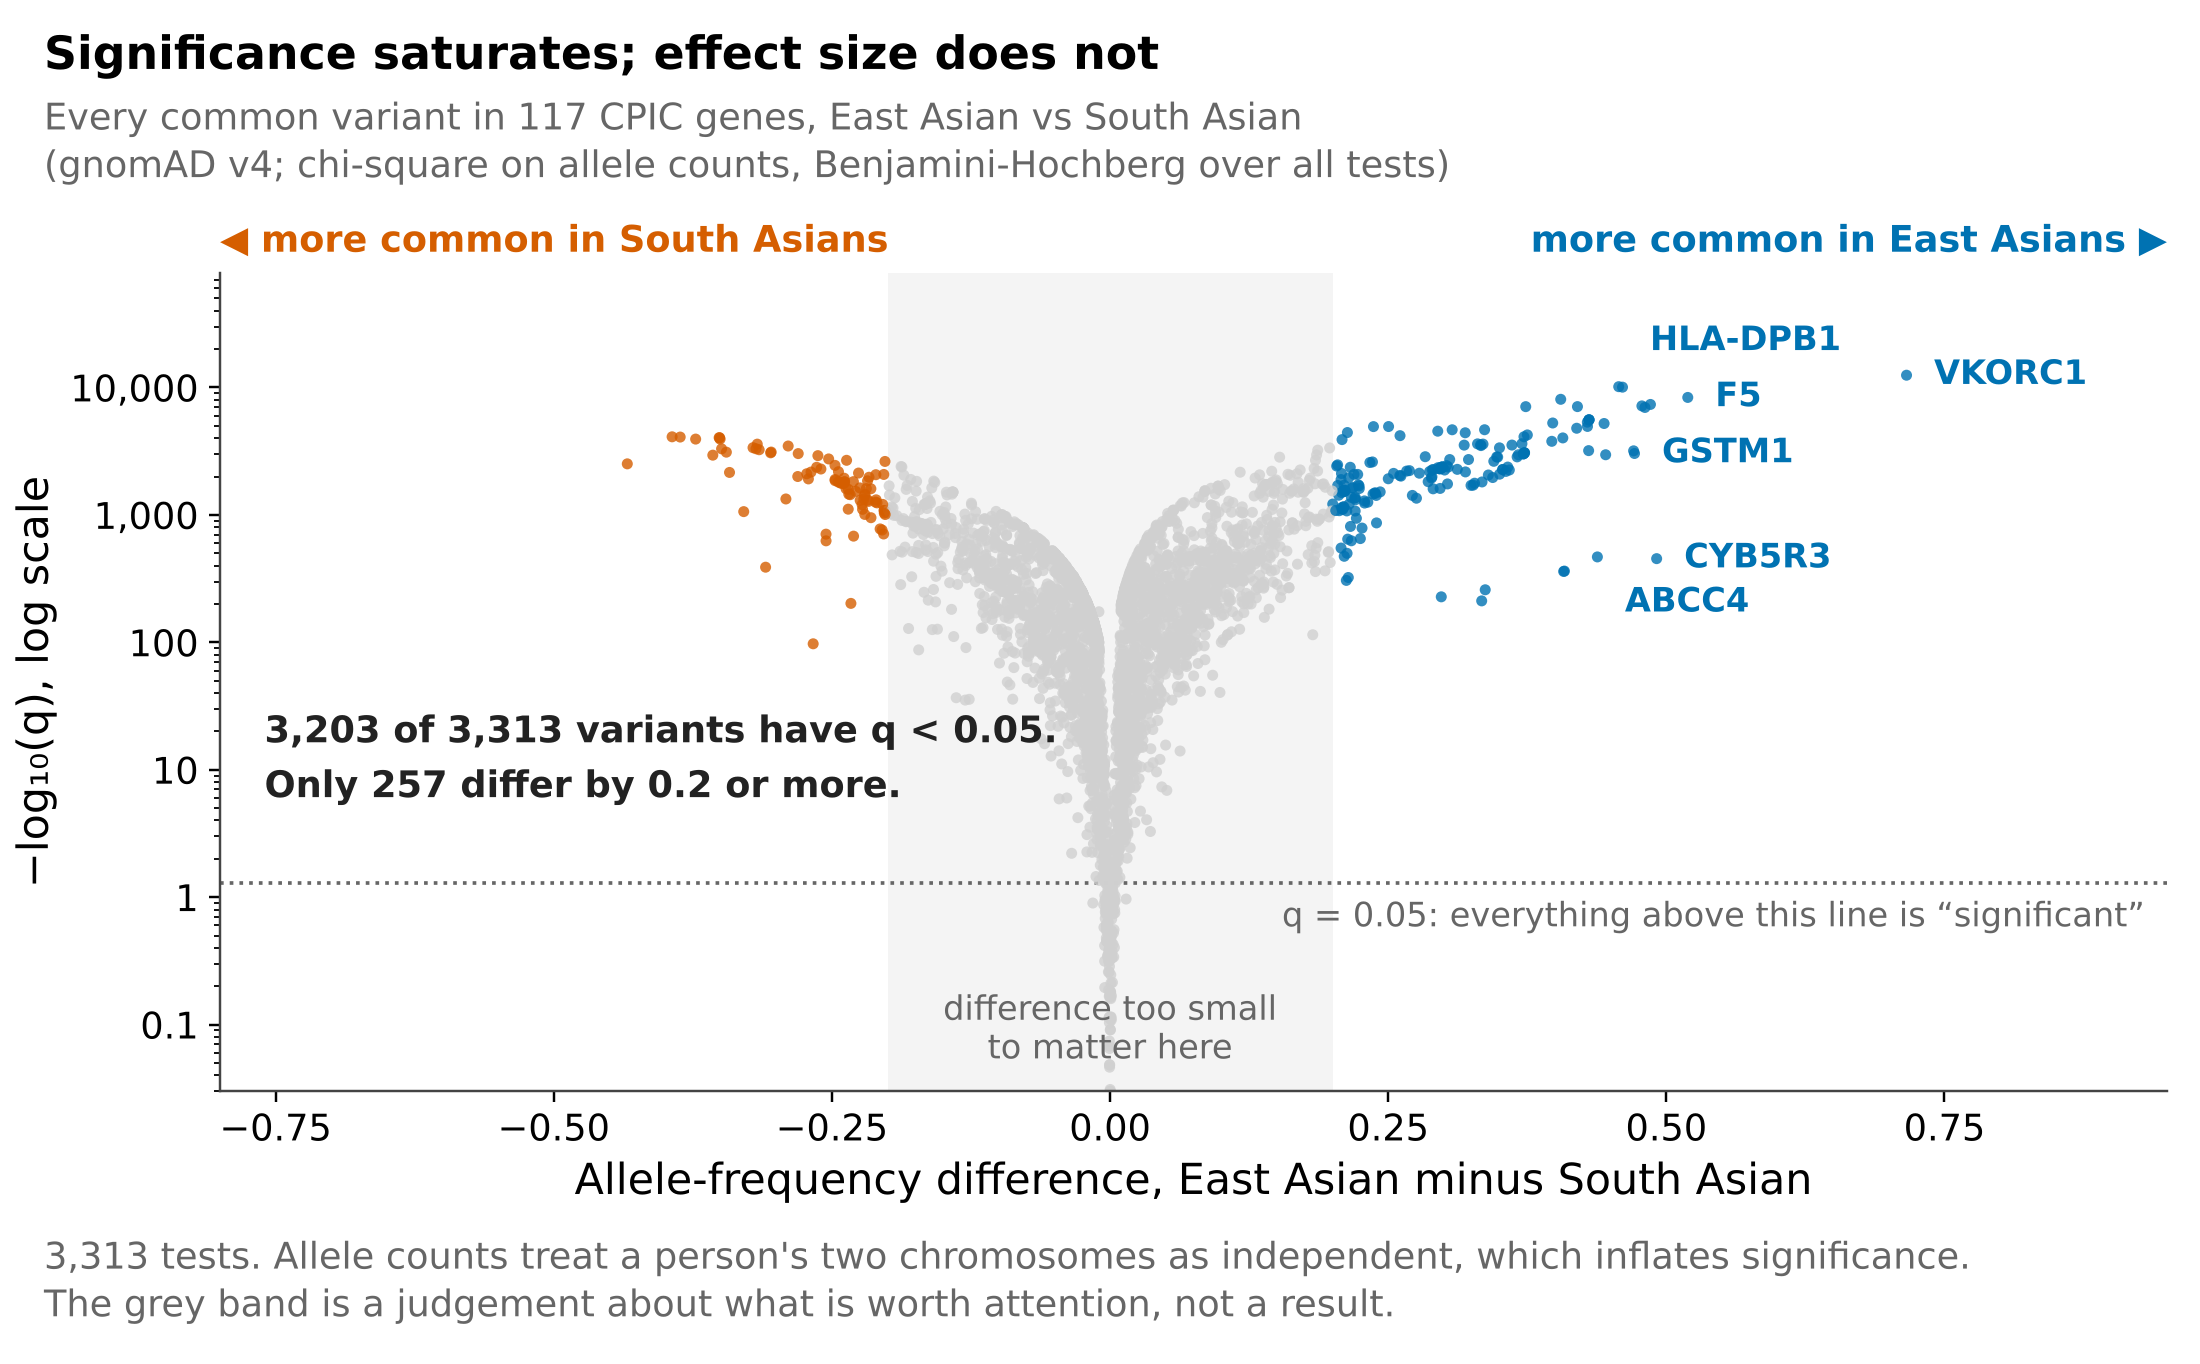

In [6]:
figure("f7_volcano")

In [7]:
n = len(variants)
sig = variants.significant.sum()
big = (variants.significant & variants.large_effect).sum()
small = variants[variants.delta.abs() >= 0.02]

print(f"variants tested          {n}")
print(f"q < 0.05                 {sig}  ({100 * sig / n:.1f}%)")
print(f"q < 0.05 and |diff| >= 0.2  {big}")
print(f"significant among variants differing by >= 2 percentage points: {small.significant.mean():.0%}")

variants tested          3313
q < 0.05                 3203  (96.7%)
q < 0.05 and |diff| >= 0.2  257
significant among variants differing by >= 2 percentage points: 100%


**Reading.** 3203 of 3313 variants are significant. Every variant differing by at least two
percentage points clears the threshold. The p-value here measures the size of gnomAD, not the size
of the difference, so it cannot select the variants worth attention. Every ranking in this project
therefore uses effect size.

One caveat: the test counts alleles, so a person's two chromosomes are treated as independent
observations. That inflates significance further and is a second reason not to rank by p.

## 7. Do guideline genes diverge more

Question 2. Level A genes have an actionable dosing guideline. If pharmacogenomic guidelines were
tracking population differences, level A genes should be more divergent. Figure F3 compares the
three distributions as cumulative curves, which shows the whole distribution rather than a
summary of it.

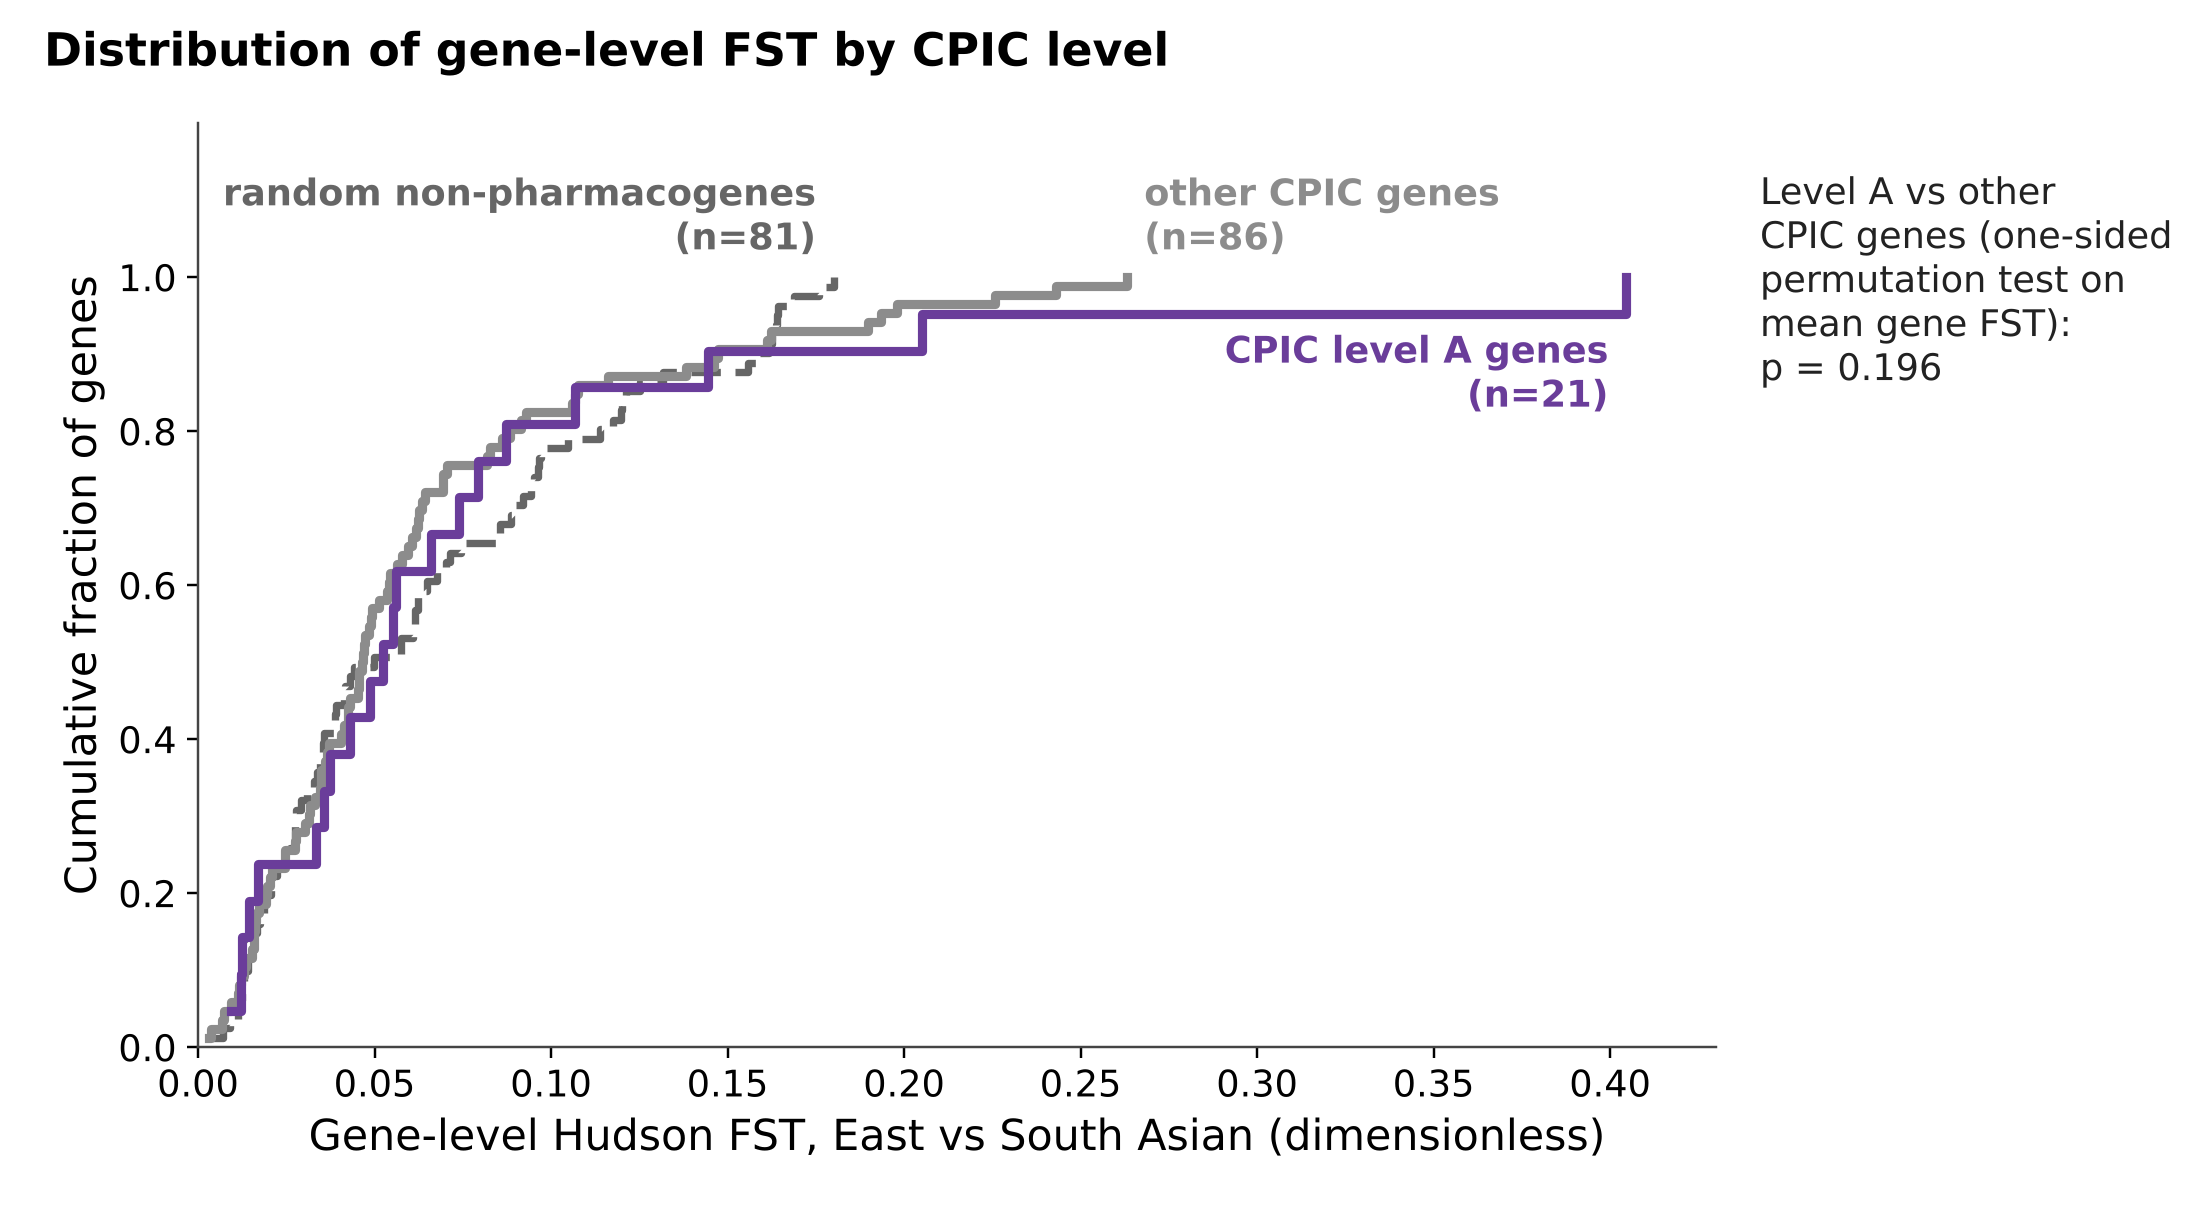

In [8]:
figure("f3_levelA_vs_rest")

In [9]:
def permutation_difference(values, label, n_perm=10000, seed=0):
    rng = np.random.default_rng(seed)
    observed = values[label].mean() - values[~label].mean()
    null = np.array([
        (lambda s: values[s].mean() - values[~s].mean())(rng.permutation(label))
        for _ in range(n_perm)
    ])
    return observed, (np.sum(null >= observed) + 1) / (n_perm + 1)

observed, p = permutation_difference(genes.fst.to_numpy(), genes.level_A.to_numpy())

print(f"level A      n={genes.level_A.sum():3d}  median FST {genes[genes.level_A].fst.median():.4f}")
print(f"other CPIC   n={(~genes.level_A).sum():3d}  median FST {genes[~genes.level_A].fst.median():.4f}")
print(f"random genes n={len(background):3d}  median FST {background.fst.median():.4f}")
print(f"\nmean difference {observed:.4f}, one-sided permutation p = {p:.3f}")

level A      n= 21  median FST 0.0524
other CPIC   n= 86  median FST 0.0465
random genes n= 81  median FST 0.0498

mean difference 0.0133, one-sided permutation p = 0.196


**Reading.** The three curves sit on top of one another. There is no evidence that level A genes
diverge more than other pharmacogenes, and none that pharmacogenes as a class diverge more than
random genes (question 4, median 0.047 against 0.050, one-sided permutation p = 0.53 in
`06_baseline_and_levels.py`).

Say "no evidence of a difference", not "no difference". With 21 level A genes and 81 random genes
the test would miss a small effect.

This null is the useful part of the story. Guidelines are written where the clinical consequence is
known, not where the population difference is largest.

## 8. Divergence by evidence level

The same question with four ordered categories instead of two.

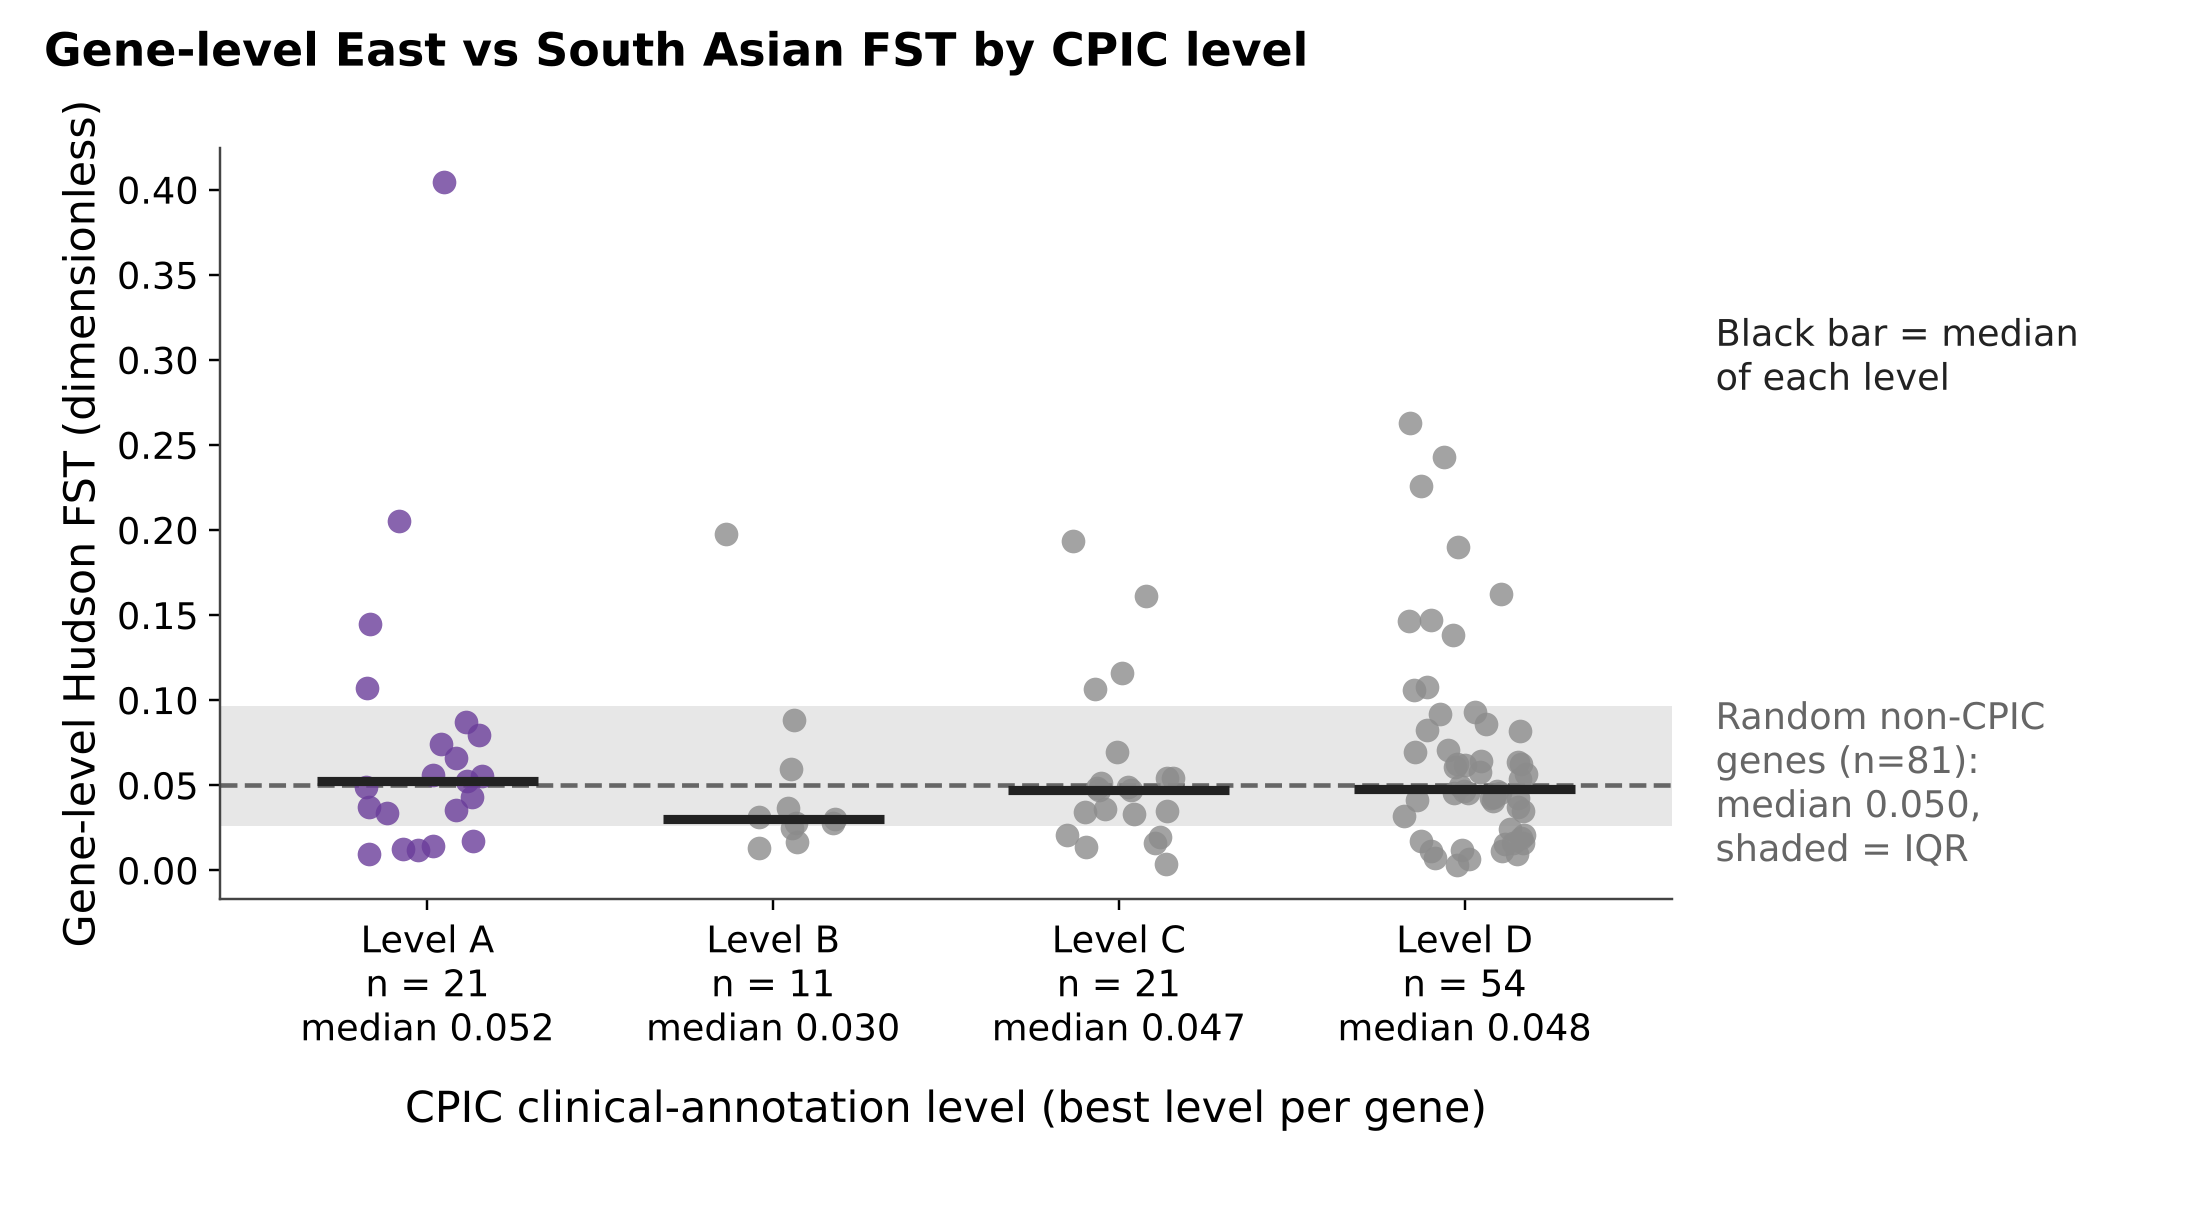

In [10]:
figure("f5_fst_by_level")

In [11]:
levels.groupby("level").fst.agg(genes="size", median="median",
                                q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75))

,genes,median,q25,q75
level,,,,
A,21,0.052,0.034,0.079
B,11,0.030,0.026,0.048
C,21,0.047,0.033,0.054
D,54,0.048,0.026,0.082


**Reading.** No trend across A, B, C and D. Spearman's rho against level rank is 0.05 with a
permutation p of 0.64. The points are drawn individually because four boxplots would hide how few
genes sit behind level B.

## 9. Population structure

Question 4 asked whether pharmacogenes behave differently as a class. A second way to ask it: if we
place the eight gnomAD groups using only pharmacogene allele frequencies, do we get a different
picture than with random genes?

The right panel is Procrustes-aligned to the left, so the two layouts can be compared directly.

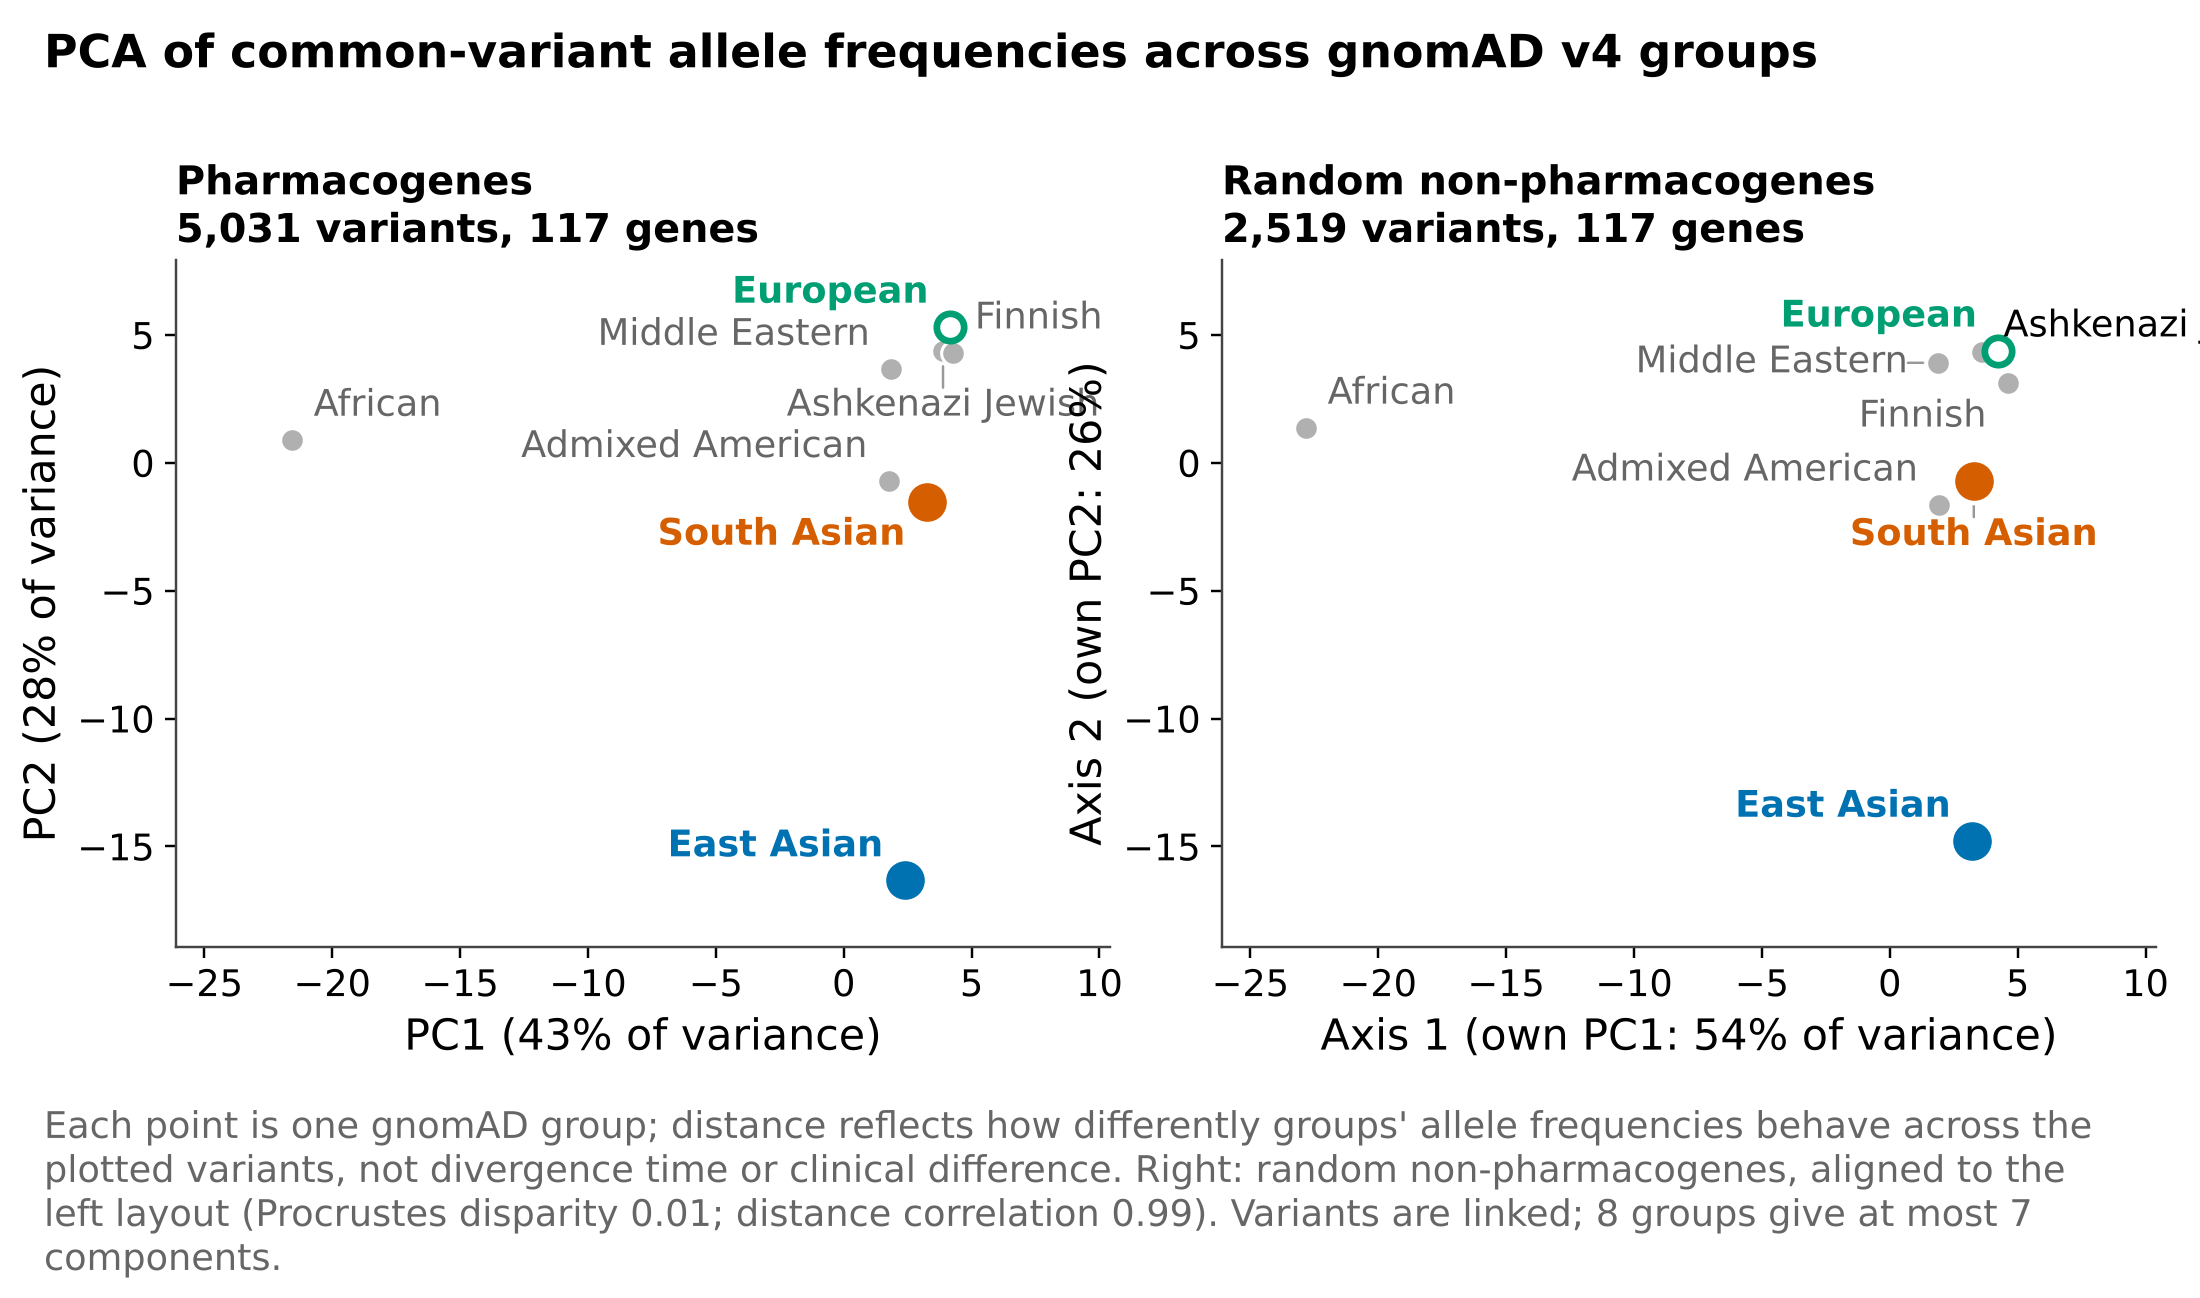

In [12]:
figure("f6_population_pca")

In [13]:
control = pd.read_csv(PROC / "pca_control_summary.csv").set_index("metric")
variance = pd.read_csv(PROC / "pca_variance.csv").set_index("pc")

print("variance explained")
print((100 * variance.head(3)).round(1).to_string())
print(f"\nProcrustes disparity, pharmacogenes vs random genes: "
      f"{control.loc['procrustes_full_background', 'pharma_draw_mean']:.3f}")
print(f"correlation between the two distance matrices:        "
      f"{control.loc['dist_corr_full_background', 'pharma_draw_mean']:.3f}")

variance explained
     pharmacogenes  background
pc                            
PC1           43.4        54.4
PC2           28.2        25.6
PC3           10.0         6.9

Procrustes disparity, pharmacogenes vs random genes: 0.010
correlation between the two distance matrices:        0.989


**Reading.** The same arrangement either way. African groups separate on the first axis, East
Asian on the second, and the pharmacogene layout reproduces the random-gene layout with a distance
correlation of 0.99. Pharmacogenes carry the same population structure as the rest of the genome.

Two limits on what a PCA like this can say. Eight groups give at most seven components, so the
percentages are descriptive. And distance in a PCA is meaningful, unlike in t-SNE or UMAP, but the
axes themselves are not interpretable quantities.

The control in `07_population_pca.py` repeatedly draws 1000 variants from each set, so the
comparison is not driven by the pharmacogene set having twice as many variants.

## 10. Who carries a variant with a guideline

Question 3. This is where a population difference becomes a clinical difference. For each
gene-drug pair we take the curated set of variants that CPIC calls no-function or decreased-function,
and compute the fraction of people carrying at least one copy, assuming Hardy-Weinberg equilibrium.

Rows are sorted by the gap between East and South Asian carrier rates.

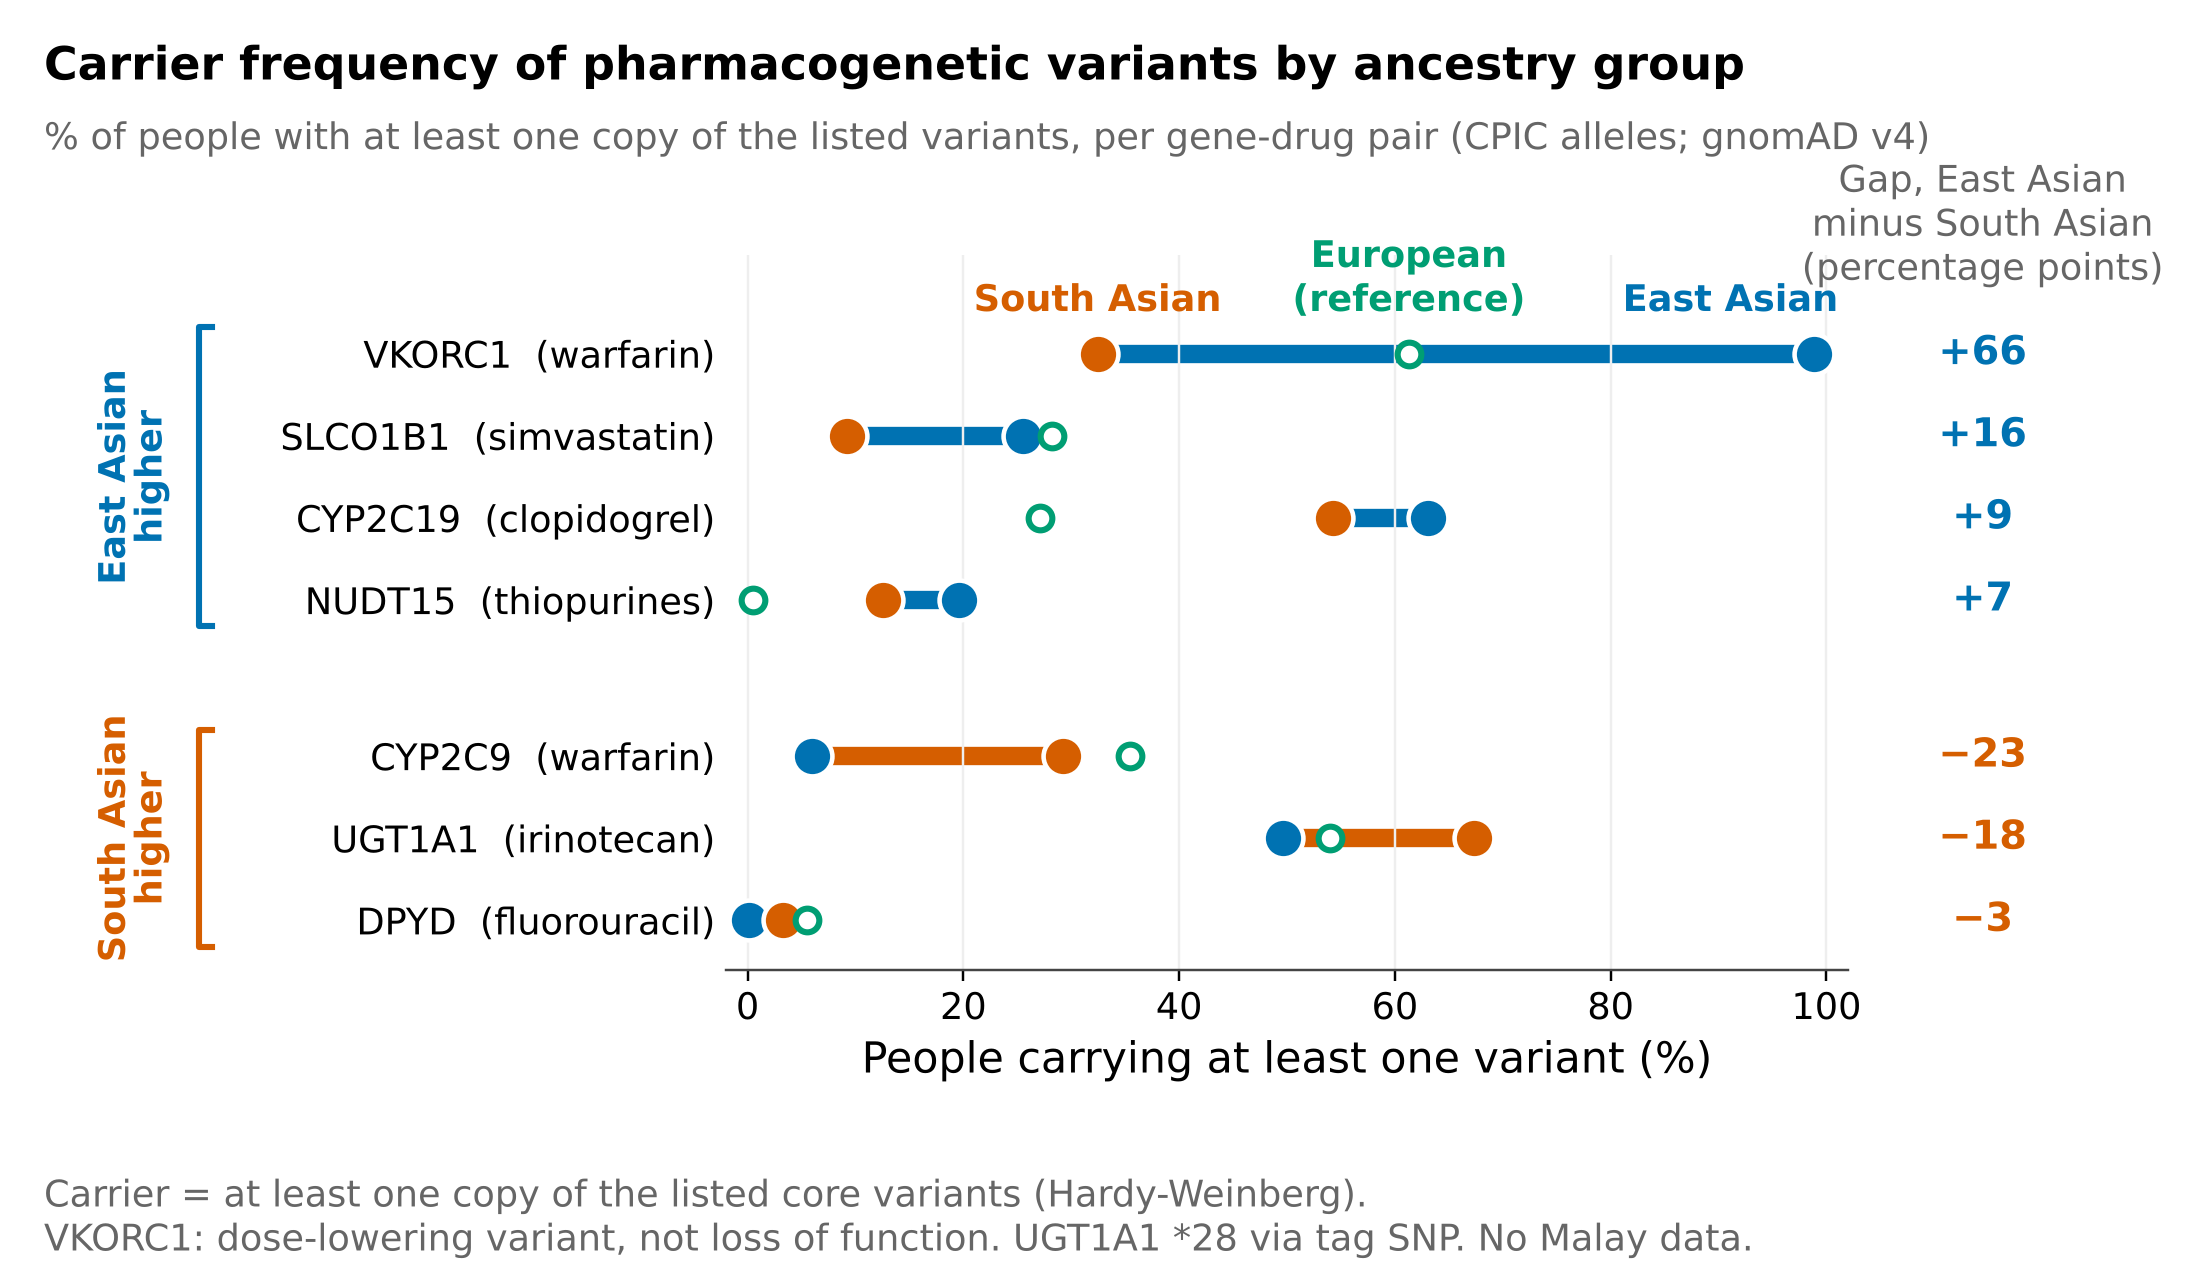

In [14]:
figure("f4_carrier_rates")

In [15]:
table = (carriers.pivot_table(index=["gene", "drug"], columns="pop", values="carrier")
          .loc[:, ["eas", "sas", "nfe"]] * 100)
table["gap (pp)"] = table.eas - table.sas
table.rename(columns={"eas": "East Asian %", "sas": "South Asian %", "nfe": "European %"}) \
     .sort_values("gap (pp)", ascending=False).round(1)

,pop,East Asian %,South Asian %,European %,gap (pp)
gene,drug,,,,
VKORC1,warfarin,98.8,32.4,61.3,66.4
SLCO1B1,simvastatin,25.6,9.2,28.2,16.4
CYP2C19,clopidogrel,63.1,54.3,27.1,8.8
NUDT15,thiopurines,19.6,12.5,0.5,7.1
CYP3A5,tacrolimus,93.1,92.6,99.6,0.5
DPYD,fluorouracil,0.1,3.3,5.5,-3.2
UGT1A1,irinotecan,49.7,67.4,54.0,-17.7
CYP2C9,warfarin,6.0,29.2,35.5,-23.2


**Reading.** VKORC1 is the extreme case: 99% of East Asians carry a warfarin-sensitivity variant
against 32% of South Asians, a gap of 66 percentage points. CYP2C9 and UGT1A1 are the next largest
and run the other way: 23 and 18 points higher in South Asians.

The ordering is by absolute gap, which compresses DPYD: 0.1% against 3.3% is a small gap in
percentage points and a 27-fold relative difference. Both readings are legitimate and the choice of
ordering decides which one the reader sees first.

DPYD is also under-counted here, because only 2 of its 4 curated variants were retrievable.

## 11. Appendix: the variant-level view

Figure F2 plots each variant's frequency in one group against the other. Points on the diagonal are
equally common in both. It is the raw material behind the gene-level ranking.

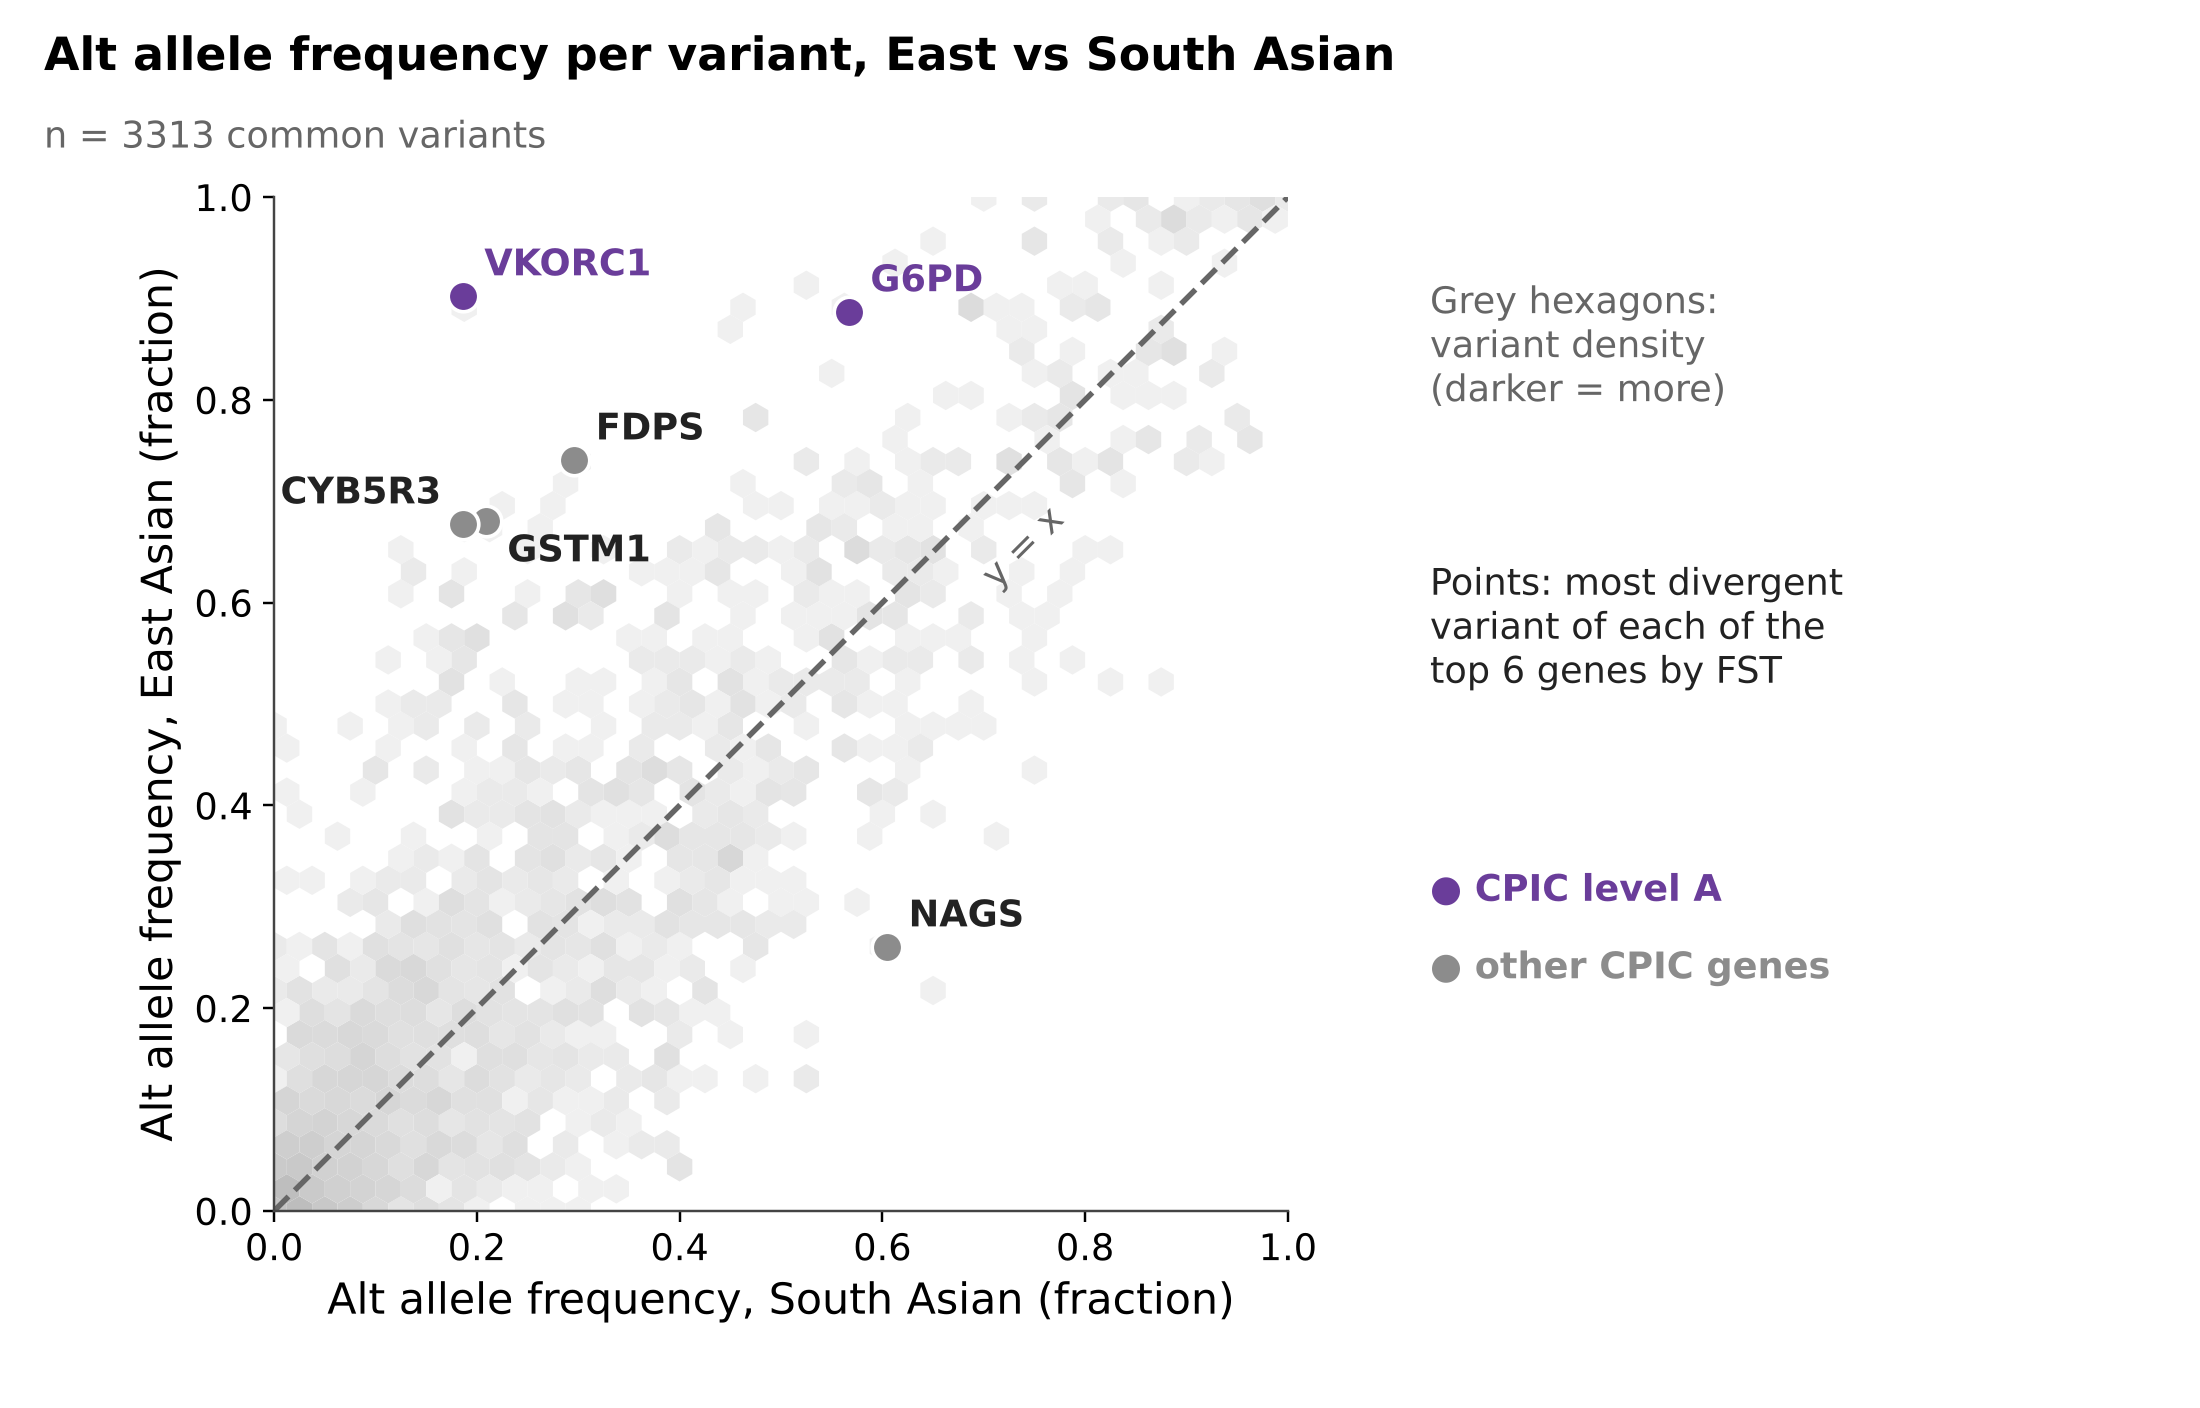

In [16]:
figure("f2_allele_freq_scatter")

## 12. Limits

| Limitation | What it limits |
| --- | --- |
| Reference groups, not residents | Results describe gnomAD reference populations, not any country's population |
| No Malay group | One of the three Singaporean communities cannot be assessed with open data |
| Groups compared by label | Nothing here supports an inference about an individual |
| Frequency is not drug response | A guideline may apply; a change in outcome is not implied |
| Only 81 random genes | A small class-level difference could be missed |
| Some genes unreadable | CYP2D6, HLA genes, TPMT and CYP2B6 need haplotypes or copy number; DPYD is under-counted |
| Alleles counted, not people | p-values are inflated, which is why rankings use effect size |

## 13. Reproducing this analysis

From the repository root. Steps 1 and 2 need network access and take about an hour.

```bash
python3 scripts/01_pull_cpic_genes.py
python3 scripts/02_pull_gnomad.py background
python3 scripts/02_pull_gnomad.py pharmacogenes
python3 scripts/03_analyse.py            # gene FST, F1, F2, F3
python3 scripts/04_carrier_rates.py
python3 scripts/05_carrier_figure.py     # F4
python3 scripts/06_baseline_and_levels.py  # baseline, levels, F5
python3 scripts/07_population_pca.py     # F6
python3 scripts/08_variant_tests.py      # per-variant tests, F7
```

Seeds are fixed at 0 and `docs/04-analysis-workflow.md` covers the pipeline stage by stage.